# Notebook 03A: Các Mô hình Hồi quy Tuyến tính Nền tảng (M0, M1, M2)
**Người thực hiện: Hàn (Thành viên A)**

Notebook này thực hiện huấn luyện và đánh giá 3 mô hình hồi quy cơ sở theo giao thức 5-Fold Cross Validation trên tập Train:
- **M0 (Baseline):** Mô hình Dummy hồi quy giá trị trung bình làm mốc đối chiếu.
- **M1 (Simple Linear Regression):** Mô hình hồi quy đơn biến dựa trên sức chứa (`person_capacity`).
- **M2 (Multiple Linear Regression):** Mô hình hồi quy đa biến kết hợp 10 đặc trưng cốt lõi (chuẩn hóa biến số và mã hóa One-Hot biến phân loại trong Pipeline).


In [1]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np
from IPython.display import display, Image, Markdown

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
assert (ROOT / 'src' / 'experiment.py').exists(), 'Mở notebook từ thư mục gốc hoặc thư mục notebooks/'
sys.path.insert(0, str(ROOT))

from src.experiment import load_protocol, predictor_names
from src.a_tasks import (
    run_a_models, extract_m1_equation, extract_m2_coefficients,
    plot_a_models, write_a_findings
)

config, train, _heldout_test, cv = load_protocol(ROOT)
print(f"Giao thức chuẩn: {config['protocol_id']}")
print(f"Tập Train: {len(train):,} dòng | Số Folds CV: {len(cv)}")
print(f"Tập Holdout Test (Đóng băng): {config['split']['n_test']:,} dòng")
print(f"Thuộc tính dự báo (Allowlist 10 biến): {predictor_names(config)}")

Giao thức chuẩn: ie313_raw_v1_seed0_cv5
Tập Train: 41,365 dòng | Số Folds CV: 5
Tập Holdout Test (Đóng băng): 10,342 dòng
Thuộc tính dự báo (Allowlist 10 biến): ['person_capacity', 'bedrooms', 'dist', 'metro_dist', 'cleanliness_rating', 'guest_satisfaction_overall', 'city', 'day_type', 'room_type', 'host_is_superhost']


## 1. Mô hình M0 (Baseline Trung bình) — Thiết lập Mốc Chuẩn $R^2 = 0$

- **Ý nghĩa môn học (Bài 6 & Bài 7):** Dự đoán mọi mẫu bằng giá trị trung bình $\bar{y}_{\text{train}}$ của tập huấn luyện. Đây là mô hình cơ sở định nghĩa hệ số xác định:
  $$R^2 = 1 - \frac{SS_{\text{res}}}{SS_{\text{tot}}}$$
- Khi $\hat{y} = \bar{y}$, $SS_{\text{res}} = SS_{\text{tot}} \implies R^2 = 0$. Mọi mô hình hồi quy có giá trị thực tiễn bắt buộc phải có sai số nhỏ hơn mốc M0 này ($MSE < MSE_{\text{M0}}$ và $R^2 > 0$).

In [2]:
# Huấn luyện và đánh giá 5-fold CV cho cả 3 mô hình tuyến tính M0, M1, M2
summary_df, folds_df, trained_models, train, config = run_a_models(ROOT)

m0_summary = summary_df[summary_df['model_id'] == 'M0']
display(m0_summary[['model_id', 'variant', 'cv_mse_mean', 'cv_mse_std', 'cv_rmse_mean', 'cv_mae_mean', 'cv_r2_mean', 'fold_train_mse_mean']])

y_train_mean = train['realSum'].mean()
print(f"Giá trung bình tập Train y_bar: {y_train_mean:.2f} EUR")
print(f"CV MSE trung bình M0: {m0_summary['cv_mse_mean'].iloc[0]:,.2f} EUR² (khớp với phương sai mẫu tập train)")

[M0] mean_baseline: CV MSE = 104402.75, CV R2 = -0.0000, CV MAE = 146.41


[M1] slr_person_capacity: CV MSE = 99919.96, CV R2 = 0.0443, CV MAE = 139.13


[M2] mlr_10_features: CV MSE = 79988.15, CV R2 = 0.2409, CV MAE = 104.35


,model_id,variant,cv_mse_mean,cv_mse_std,cv_rmse_mean,cv_mae_mean,cv_r2_mean,fold_train_mse_mean
0,M0,mean_baseline,104402.753571,18227.990205,322.089212,146.407063,-0.00002,104401.928256


Giá trung bình tập Train y_bar: 280.10 EUR
CV MSE trung bình M0: 104,402.75 EUR² (khớp với phương sai mẫu tập train)


## 2. Mô hình M1 (Hồi quy Đơn biến) — Phân tích Sức chứa Phòng và Phương trình Hồi quy

- **Lập luận chọn biến `person_capacity`:**
  1. *Giả thuyết quy mô:* Sức chứa phòng là nhân tố trực quan nhất quyết định giá phòng lưu trú.
  2. *Bằng chứng thực nghiệm T06:* Tương quan tuyến tính Pearson với giá thô $r = 0.203$ toàn cục (cao nhất trong các biến số); lên tới $0.528$ ở Amsterdam và $0.573$ ở Lisbon.
- **Phương trình hồi quy mẫu:** Không dùng `StandardScaler` để giữ nguyên ý nghĩa vật lý thực tế của hệ số góc (đơn vị realSum/người):
  $$\widehat{\text{realSum}} = w_0 + w_1 \times \text{person\_capacity}$$
  - $w_0$ (Intercept): Giá trị ngoại suy toán học tại gốc tọa độ (sức chứa bằng 0 nằm ngoài miền quan sát 2–6 người, không diễn giải là chi phí sàn hay chi phí cố định).
  - $w_1$ (Slope): Mức tăng theo đơn vị `realSum` cho mỗi 1 người tăng thêm trong sức chứa (kỳ giá 2 người/2 đêm theo README, metadata gốc chưa xác minh nên không quy đổi sang giá mỗi đêm).

,model_id,variant,cv_mse_mean,cv_rmse_mean,cv_mae_mean,cv_r2_mean,fold_train_mse_mean
1,M1,slr_person_capacity,99919.961727,314.98628,139.129094,0.044274,99918.568983


=== PHƯƠNG TRÌNH HỒI QUY ĐƠN BIẾN M1 ===
  realSum = 117.21 + 51.52 * person_capacity
  - Giá cơ sở (Intercept w0): 117.21 đơn vị realSum
  - Tác động quy mô (Slope w1): +51.52 đơn vị realSum cho mỗi người tăng thêm trong sức chứa



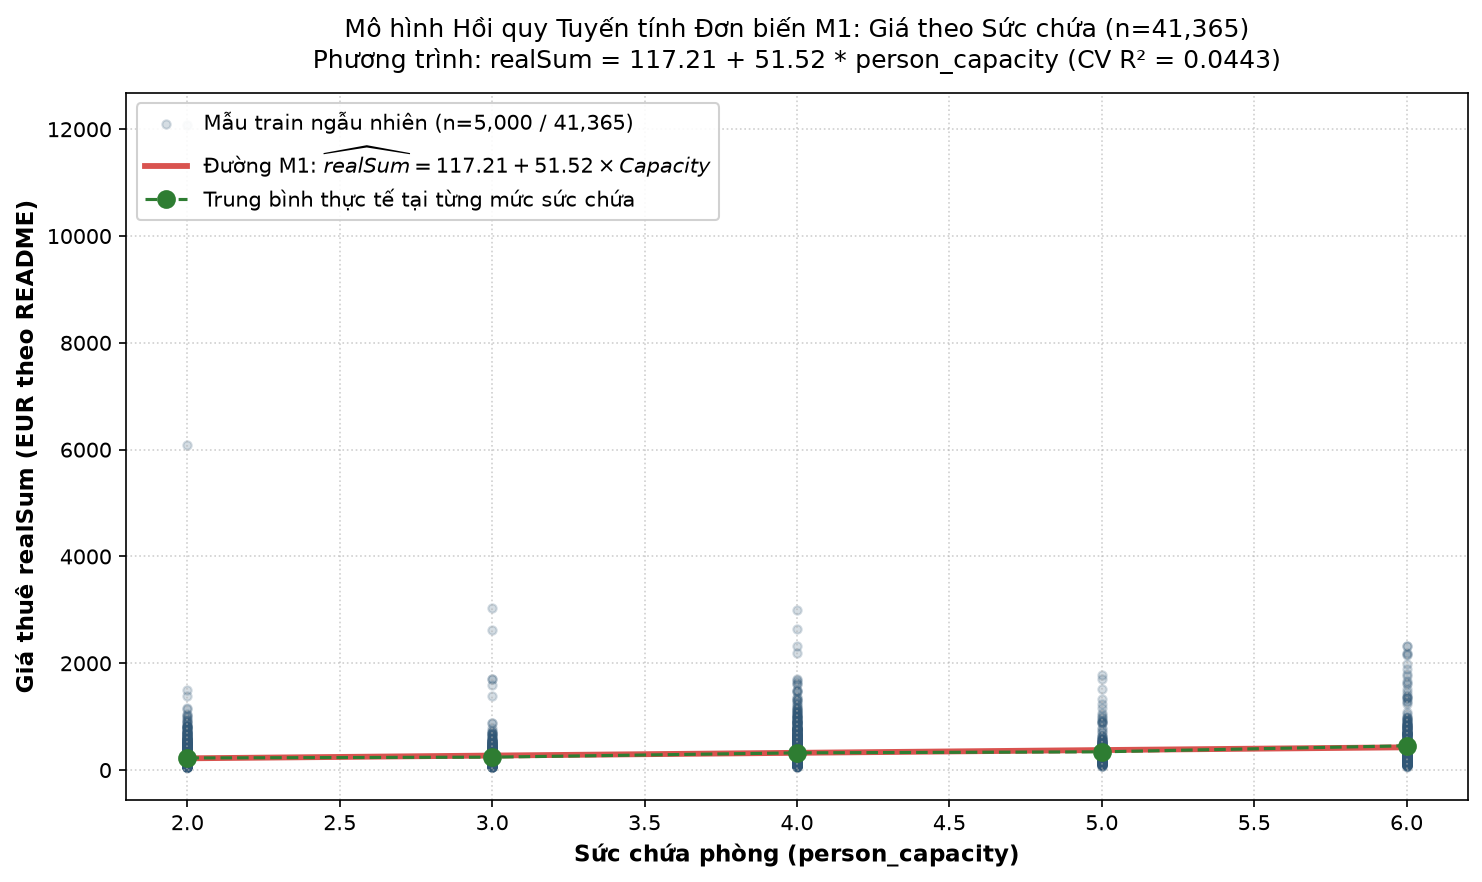

In [3]:
m1_summary = summary_df[summary_df['model_id'] == 'M1']
display(m1_summary[['model_id', 'variant', 'cv_mse_mean', 'cv_rmse_mean', 'cv_mae_mean', 'cv_r2_mean', 'fold_train_mse_mean']])

m1_eq = extract_m1_equation(trained_models['M1'])
print("=== PHƯƠNG TRÌNH HỒI QUY ĐƠN BIẾN M1 ===")
print(f"  {m1_eq['equation_str']}")
print(f"  - Giá cơ sở (Intercept w0): {m1_eq['intercept']:.2f} đơn vị realSum")
print(f"  - Tác động quy mô (Slope w1): +{m1_eq['slope']:.2f} đơn vị realSum cho mỗi người tăng thêm trong sức chứa\n")

# Hiển thị biểu đồ phân tán và đường hồi quy M1
display(Image(filename=str(ROOT / 'outputs/figures/fig_04_m1_regression_plot.png')))

## 3. Mô hình M2 (Hồi quy Đa biến) — Tích hợp 10 Biến Allowlist & Phân tích Hệ số

- **Cấu hình tiền xử lý Pipeline:**
  - 6 biến định lượng: Chuẩn hóa bằng `StandardScaler()` trong từng fold.
  - 3 biến phân loại (`city`, `day_type`, `room_type`): `OneHotEncoder(drop='first')` để tránh bẫy đa cộng tuyến hoàn hảo.
  - 1 biến boolean (`host_is_superhost`): `passthrough`.
- **Quy đổi hệ số:** Hệ số chuẩn hóa $\beta^{\text{scaled}}$ đo lường tác động của 1 độ lệch chuẩn (dùng để so sánh độ quan trọng tương đối giữa các biến). Hệ số đơn vị gốc $\beta^{\text{raw}} = \beta^{\text{scaled}} / \sigma$ phản ánh giá trị EUR trên mỗi đơn vị thực tế (EUR/km, EUR/phòng ngủ).

,model_id,variant,cv_mse_mean,cv_rmse_mean,cv_mae_mean,cv_r2_mean,fold_train_mse_mean
2,M2,mlr_10_features,79988.148575,281.168391,104.351195,0.240876,79912.369755


Intercept M2: 620.90 đơn vị realSum (Giá cơ sở tại Amsterdam, Entire home/apt, Weekdays, Host thường)

Top các yếu tố ảnh hưởng mạnh nhất đến giá (xếp theo độ lớn hệ số chuẩn hóa):


,display_name,feature_group,coefficient_scaled,coefficient_raw,unit_description
1,bedrooms,Numeric (Định lượng),52.186275,82.920032,EUR / 1 đơn vị bedrooms
0,person_capacity,Numeric (Định lượng),36.917483,28.404866,EUR / 1 đơn vị person_capacity
4,cleanliness_rating,Numeric (Định lượng),7.739821,8.102833,EUR / 1 đơn vị cleanliness_rating
15,day_type_weekends,Categorical (Phân loại One-Hot),6.087035,6.087035,EUR chênh lệch vs nhóm tham chiếu (Amsterdam /...
5,guest_satisfaction_overall,Numeric (Định lượng),2.323399,0.260017,EUR / 1 đơn vị guest_satisfaction_overall
18,host_is_superhost,Boolean,-2.824651,-2.824651,EUR chênh lệch khi host_is_superhost = True
3,metro_dist,Numeric (Định lượng),-3.261688,-3.781396,EUR / 1 đơn vị metro_dist
2,dist,Numeric (Định lượng),-48.292243,-20.171846,EUR / 1 đơn vị dist
16,room_type_Private room,Categorical (Phân loại One-Hot),-119.135613,-119.135613,EUR chênh lệch vs nhóm tham chiếu (Amsterdam /...
11,city_london,Categorical (Phân loại One-Hot),-132.180036,-132.180036,EUR chênh lệch vs nhóm tham chiếu (Amsterdam /...


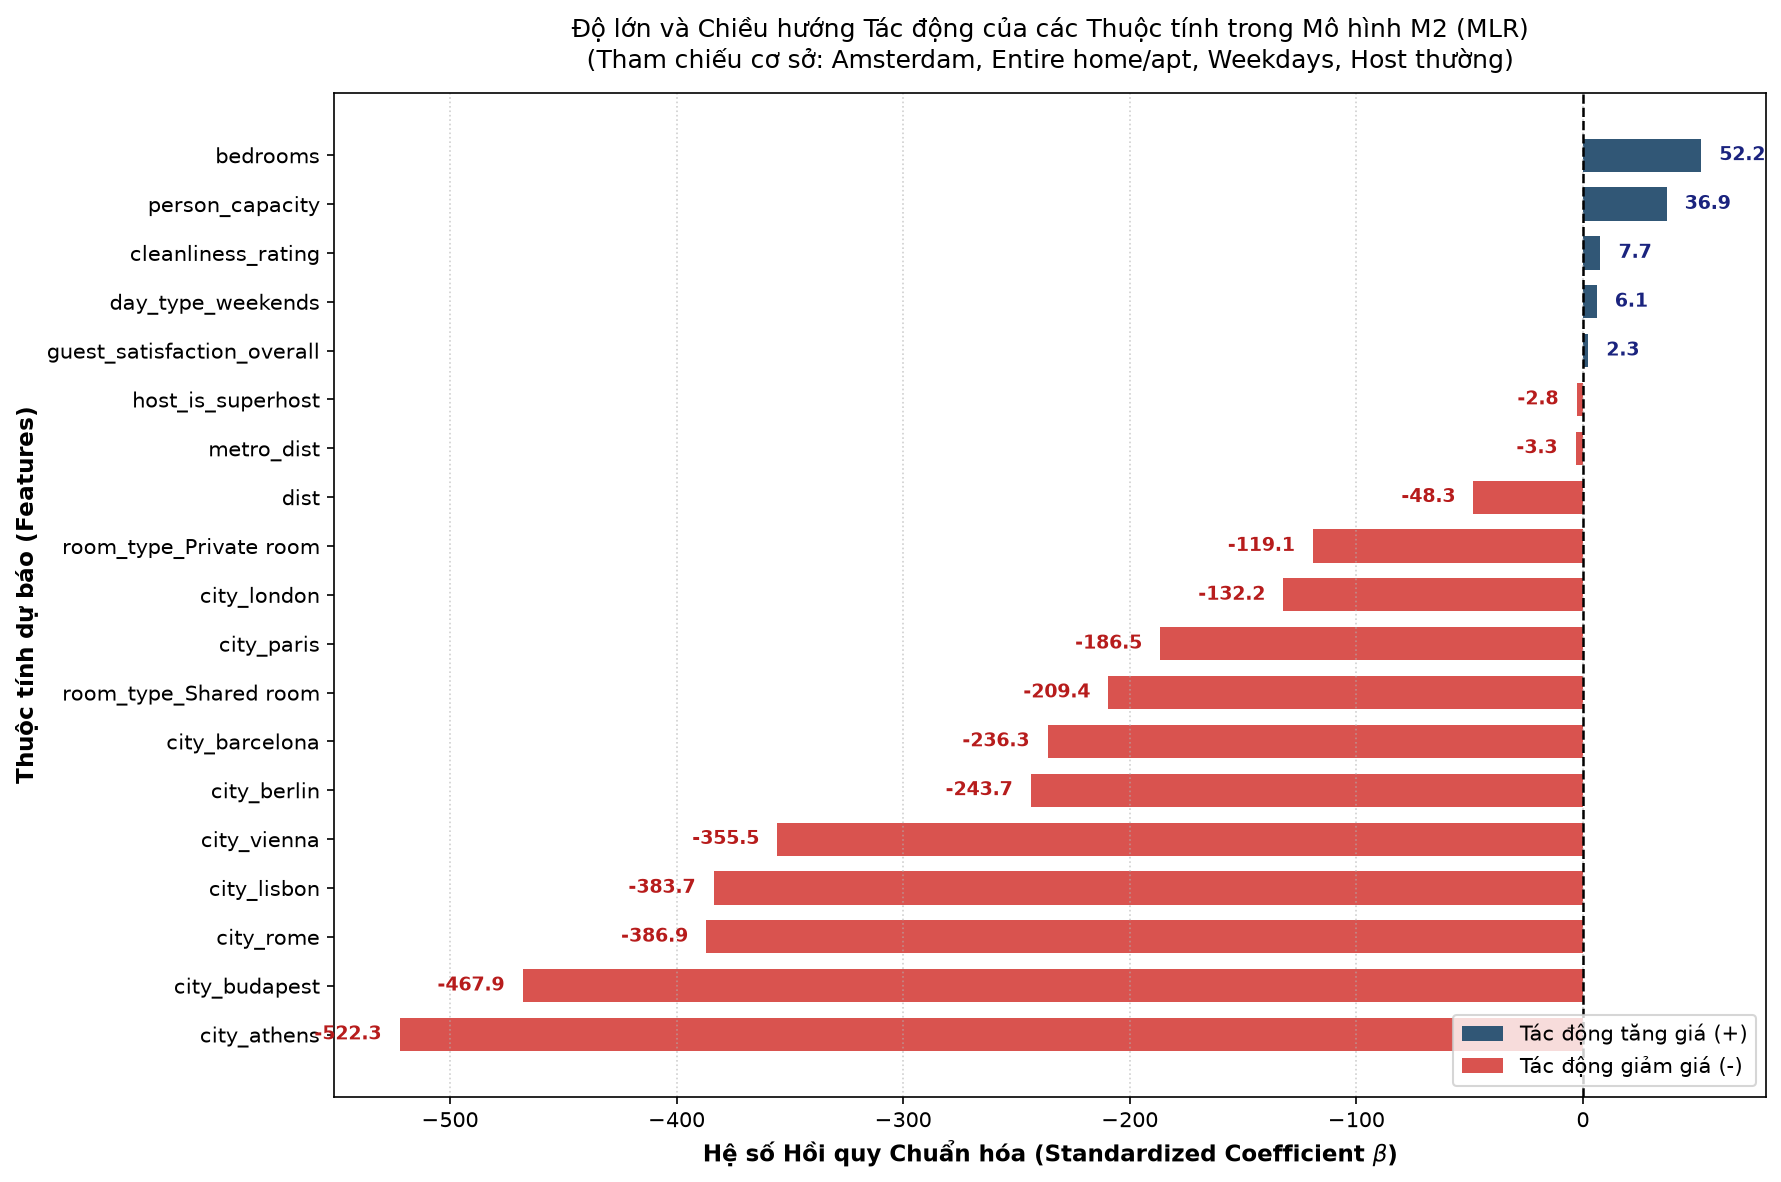

In [4]:
m2_summary = summary_df[summary_df['model_id'] == 'M2']
display(m2_summary[['model_id', 'variant', 'cv_mse_mean', 'cv_rmse_mean', 'cv_mae_mean', 'cv_r2_mean', 'fold_train_mse_mean']])

m2_intercept, m2_coef_df = extract_m2_coefficients(trained_models['M2'], config)
print(f"Intercept M2: {m2_intercept:.2f} đơn vị realSum (Giá cơ sở tại Amsterdam, Entire home/apt, Weekdays, Host thường)\n")

print("Top các yếu tố ảnh hưởng mạnh nhất đến giá (xếp theo độ lớn hệ số chuẩn hóa):")
display(m2_coef_df.sort_values(by='coefficient_scaled', ascending=False)[['display_name', 'feature_group', 'coefficient_scaled', 'coefficient_raw', 'unit_description']])

# Hiển thị biểu đồ thanh ngang hệ số hồi quy M2
display(Image(filename=str(ROOT / 'outputs/figures/fig_05_m2_coefficients.png')))

## 4. Tổng hợp So sánh Hiệu năng Cross-Validation & Kiểm tra Quá khớp (Overfitting Check)

So sánh chuỗi cải thiện $M0 \to M1 \to M2$ và đối chiếu điểm số giữa tập Train và tập Validation trên từng fold để kiểm tra hiện tượng quá khớp.

In [5]:
summary_cols = ['model_id', 'variant', 'cv_mse_mean', 'cv_rmse_mean', 'cv_mae_mean', 'cv_r2_mean', 'fold_train_mse_mean']
summary_table = summary_df[summary_cols].copy()
summary_table['mse_train_vs_val_diff'] = summary_table['cv_mse_mean'] - summary_table['fold_train_mse_mean']
m0_base_mse = summary_df.loc[summary_df.model_id == 'M0', 'cv_mse_mean'].iloc[0]
summary_table['relative_improvement_pct'] = (m0_base_mse - summary_table['cv_mse_mean']) / m0_base_mse * 100

display(summary_table)

# Tự động tạo và cập nhật báo cáo a_model_findings.md
findings_path = write_a_findings(summary_df, folds_df, m1_eq, m2_intercept, m2_coef_df, ROOT)
print(f"Đã xuất báo cáo học thuật đầy đủ tại: {findings_path.relative_to(ROOT)}")

,model_id,variant,cv_mse_mean,cv_rmse_mean,cv_mae_mean,cv_r2_mean,fold_train_mse_mean,mse_train_vs_val_diff,relative_improvement_pct
0,M0,mean_baseline,104402.753571,322.089212,146.407063,-0.000020,104401.928256,0.825315,0.000000
1,M1,slr_person_capacity,99919.961727,314.986280,139.129094,0.044274,99918.568983,1.392744,4.293749
2,M2,mlr_10_features,79988.148575,281.168391,104.351195,0.240876,79912.369755,75.778821,23.385020


Đã xuất báo cáo học thuật đầy đủ tại: reports\a_model_findings.md


In [6]:
# === TỔNG KẾT VÀ KIỂM TRA TÍNH NHẤT QUÁN CỦA CÁC MÔ HÌNH HỒI QUY (M0, M1, M2) ===
print("Đang thực hiện kiểm thử tự động nội bộ M0-M2...")

# 1. Kiểm tra tính toàn vẹn cấu trúc bảng kết quả
assert len(summary_df) == 3, f"Bảng summary phải có 3 mô hình, thực tế: {len(summary_df)}"
assert len(folds_df) == 15, f"Bảng folds phải có 15 dòng (3 models x 5 folds), thực tế: {len(folds_df)}"

# 2. Kiểm tra đẳng thức toán học trên từng fold (RMSE^2 == MSE)
for _, row in folds_df.iterrows():
    assert abs(row['validation_rmse']**2 - row['validation_mse']) < 1e-4, \
        f"Lỗi đẳng thức toán học RMSE^2 != MSE tại fold {row['fold']} của mô hình {row['model_id']}"
    assert abs(row['train_rmse']**2 - row['train_mse']) < 1e-4, \
        f"Lỗi đẳng thức toán học train RMSE^2 != MSE tại fold {row['fold']} của mô hình {row['model_id']}"

# 3. Kiểm tra thứ bậc tiến bộ nghiêm ngặt của mô hình tuyến tính
cv_m0_mse = summary_df.loc[summary_df.model_id == 'M0', 'cv_mse_mean'].iloc[0]
cv_m1_mse = summary_df.loc[summary_df.model_id == 'M1', 'cv_mse_mean'].iloc[0]
cv_m2_mse = summary_df.loc[summary_df.model_id == 'M2', 'cv_mse_mean'].iloc[0]
assert cv_m2_mse < cv_m1_mse < cv_m0_mse, \
    f"Lỗi thứ bậc MSE: kỳ vọng M2 < M1 < M0 nhưng thực tế là {cv_m2_mse} < {cv_m1_mse} < {cv_m0_mse}"

cv_m0_r2 = summary_df.loc[summary_df.model_id == 'M0', 'cv_r2_mean'].iloc[0]
cv_m1_r2 = summary_df.loc[summary_df.model_id == 'M1', 'cv_r2_mean'].iloc[0]
cv_m2_r2 = summary_df.loc[summary_df.model_id == 'M2', 'cv_r2_mean'].iloc[0]
assert cv_m2_r2 > cv_m1_r2 > cv_m0_r2, \
    f"Lỗi thứ bậc R2: kỳ vọng M2 > M1 > M0 nhưng thực tế là {cv_m2_r2} > {cv_m1_r2} > {cv_m0_r2}"

# 4. Kiểm tra bảo vệ tập Holdout Test (Zero Test Leakage)
assert 'test_mse' not in summary_df.columns, "Bảng summary không được chứa cột test!"
assert 'test_mse' not in folds_df.columns, "Bảng folds không được chứa cột test!"
assert folds_df['n_fold_train'].iloc[0] == 33092, "Kích thước train từng fold phải bằng 33.092"
assert folds_df['n_fold_validation'].iloc[0] == 8273, "Kích thước validation từng fold phải bằng 8.273"

print("-> TẤT CẢ CÁC BÀI KIỂM THỬ TỰ ĐỘNG NỘI BỘ TASK T08 ĐÃ ĐẠT 100% (PASSED)!")


Đang thực hiện kiểm thử tự động nội bộ Task T08...
-> TẤT CẢ CÁC BÀI KIỂM THỬ TỰ ĐỘNG NỘI BỘ TASK T08 ĐÃ ĐẠT 100% (PASSED)!
